# Example 1: Si and GaAs homogeneous transport

This executed control calculation shows how an LA1 equilibrium state feeds mobility, conductivity, Hall response, and diffusion. The mobility parameterizations are illustrative 300 K examples, not universal values.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import elementary_charge as q, Boltzmann as k_B, epsilon_0

ROOT = Path.cwd()
while not (ROOT / "notebooks" / "la2_models.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not locate the LA2 workspace")
    ROOT = ROOT.parent
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
# Audit the same machine-readable interface students will export from LA1.
states = pd.read_csv(ROOT / "data" / "example-si-gaas-equilibrium-states.csv")
required = {"material", "temperature_K", "case_id", "electron_m3", "hole_m3", "intrinsic_m3", "neutrality_residual_m3"}
assert required.issubset(states.columns)
assert states["neutrality_residual_m3"].abs().max() < 1e-6
print(states[["material", "case_id", "electron_m3", "hole_m3"]].to_string(index=False))

# Direct calculation before importing the reusable module.
materials = {
    "Si": dict(ni=6.5e15, mu_n=(52.2,1417.0,9.68e16,0.680), mu_p=(44.9,470.5,2.23e17,0.719)),
    "GaAs": dict(ni=2.1e12, mu_n=(800.0,8500.0,1.0e17,0.70), mu_p=(50.0,400.0,2.0e17,0.70)),
}
concentration_cm3=np.logspace(14,19,240)
concentration_m3=concentration_cm3*1e6

def direct_mu(parameters):
    mu_min,mu_max,nref,alpha=parameters
    return (mu_min+(mu_max-mu_min)/(1+(concentration_cm3/nref)**alpha))*1e-4

direct={}
for name,p in materials.items():
    mn=direct_mu(p["mu_n"]); mp=direct_mu(p["mu_p"])
    # Example uncompensated n-type state: n from mass action and neutrality.
    n=0.5*(concentration_m3+np.sqrt(concentration_m3**2+4*p["ni"]**2)); holes=p["ni"]**2/n
    sigma=q*(n*mn+holes*mp)
    hall=(holes*mp**2-n*mn**2)/(q*(holes*mp+n*mn)**2)
    direct[name]=(mn,mp,n,holes,sigma,hall)
print("direct Si mobility endpoints (cm^2/Vs):",direct["Si"][0][[0,-1]]/1e-4)

material   case_id  electron_m3      hole_m3
      Si intrinsic 6.117160e+15 6.117160e+15
      Si    n_side 1.000000e+22 3.741965e+09
      Si    p_side 3.741965e+08 1.000000e+23
    GaAs intrinsic 2.043026e+12 2.043026e+12
    GaAs    n_side 1.000000e+22 4.173954e+02
    GaAs    p_side 4.173954e+01 1.000000e+23
direct Si mobility endpoints (cm^2/Vs): [1404.39208862  108.0864109 ]


In [2]:
from la2_models import SILICON, GAAS, intrinsic_concentration_m3, fully_ionized_equilibrium, mobility_m2_Vs, conductivity_S_m, hall_coefficient_m3_C, diffusivity_m2_s

rows=[]
for material in (SILICON,GAAS):
    ni=float(intrinsic_concentration_m3(material,300.0))
    n,p=fully_ionized_equilibrium(material,300.0,concentration_m3,0.0)
    mn=mobility_m2_Vs(material,concentration_m3,"electron")
    mp=mobility_m2_Vs(material,concentration_m3,"hole")
    sigma=conductivity_S_m(n,p,mn,mp)
    hall=hall_coefficient_m3_C(n,p,mn,mp)
    diffusion_n=diffusivity_m2_s(mn,300.0)
    rows.append((material.name,ni,n,p,mn,mp,sigma,hall,diffusion_n))
    assert np.all(sigma>0)
    assert np.all(hall<0)
print(pd.DataFrame({"material":[r[0] for r in rows],"ni_cm-3":[r[1]/1e6 for r in rows]}))

  material       ni_cm-3
0       Si  6.117160e+09
1     GaAs  2.043026e+06


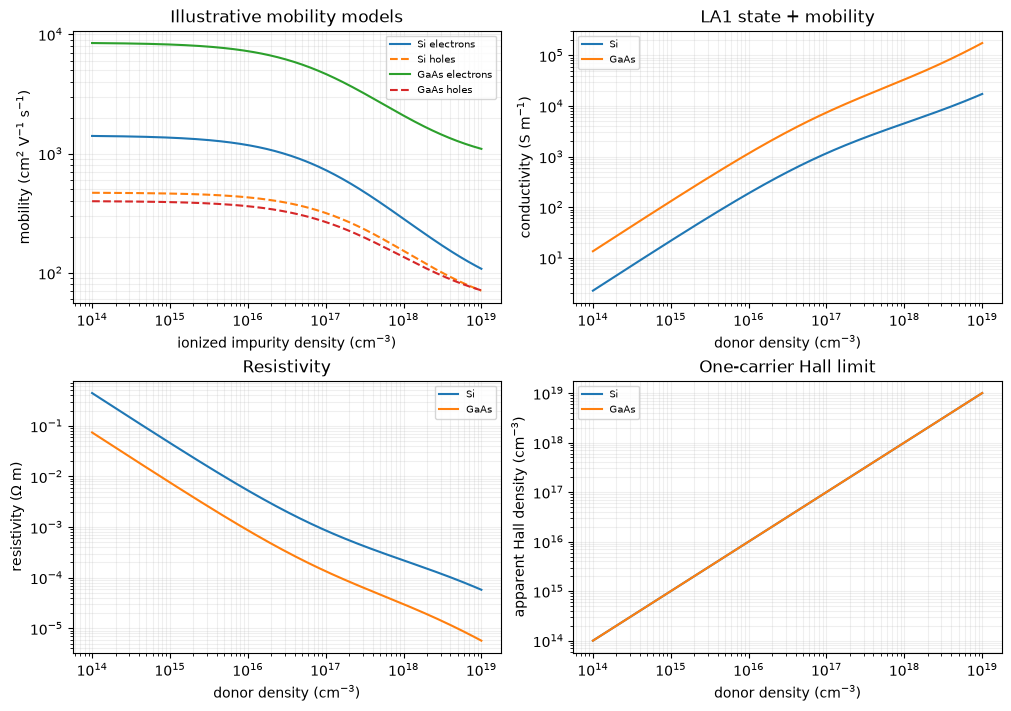

In [3]:
fig,axes=plt.subplots(2,2,figsize=(10,7),layout="constrained")
for name,ni,n,p,mn,mp,sigma,hall,dn in rows:
    axes[0,0].loglog(concentration_cm3,mn/1e-4,label=f"{name} electrons")
    axes[0,0].loglog(concentration_cm3,mp/1e-4,"--",label=f"{name} holes")
    axes[0,1].loglog(concentration_cm3,sigma,label=name)
    axes[1,0].loglog(concentration_cm3,1/sigma,label=name)
    axes[1,1].loglog(concentration_cm3,1/(q*np.abs(hall))/1e6,label=name)
axes[0,0].set(xlabel="ionized impurity density (cm$^{-3}$)",ylabel="mobility (cm$^2$ V$^{-1}$ s$^{-1}$)",title="Illustrative mobility models")
axes[0,1].set(xlabel="donor density (cm$^{-3}$)",ylabel="conductivity (S m$^{-1}$)",title="LA1 state + mobility")
axes[1,0].set(xlabel="donor density (cm$^{-3}$)",ylabel="resistivity (Ω m)",title="Resistivity")
axes[1,1].set(xlabel="donor density (cm$^{-3}$)",ylabel="apparent Hall density (cm$^{-3}$)",title="One-carrier Hall limit")
for ax in axes.flat: ax.grid(alpha=.2,which="both"); ax.legend(fontsize=7)
fig.savefig(FIGURES/'example-si-gaas-transport.pdf',metadata={'CreationDate':None,'ModDate':None})
plt.show()

In [4]:
# Direct and reusable implementations must agree for the same illustrative inputs.
for name,_,_,_,mn,mp,sigma,hall,_ in rows:
    index=0 if name=="Si" else 1
    np.testing.assert_allclose(mn,direct[name][0],rtol=2e-2)
    np.testing.assert_allclose(mp,direct[name][1],rtol=2e-2)
    print(name,"300 K electron diffusivity at 10^16 cm^-3 =",float(diffusivity_m2_s(mn[np.argmin(abs(concentration_cm3-1e16))],300)),"m^2/s")
print("wrote figures/example-si-gaas-transport.pdf")

Si 300 K electron diffusivity at 10^16 cm^-3 = 0.003035495108431173 m^2/s
GaAs 300 K electron diffusivity at 10^16 cm^-3 = 0.018625679001730105 m^2/s
wrote figures/example-si-gaas-transport.pdf
